## UMAP embedding of CDK4/6i treatment simulations

In [10]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import datetime
import glob
import joblib
import shutil
import umap

sys.path.insert(0, "cellular_cycle") # add path to the model

# should examine these functions to determine which are best to use (overlapping functionality)
from model_fxns import minmax_scale, stack_sliding_window, calc_minmax, load_sim_output, load_norm_data

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
SAVE_DIR.mkdir(exist_ok=True)

OVERWRITE = False # Overwrite existing simulation files
SET_JPARAM = False # Set the parameter values for the simulation using PSO-optimized values

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

CDK46i_SIM_DIR = Path(SAVE_DIR,'cdk46i_sims')
DOWNLOAD = True # set to true to automatically download the original data from Dropbox
GENERATE_UMAP = True # Generate UMAP plots for the simulation output

sys_type = sys.platform

### Detect computer system
NOTE: UMAP reducer files are dependent on processor, OS and package versions

### Load Data

These files were generated using original parameters and CDK4/6i at 0.4 µM 
    
**Output files from [03_ECM_model_output.ipynb](03_ECM_model_output.ipynb)**:  
```
stoch_sim_soft_erl_param_cycdi_0_4.csv
stoch_sim_int_erl_param_cycdi_0_4.csv
stoch_sim_stiff_erl_param_cycdi_0_4.csv
stoch_sim_soft_DMSO_param_cycdi_0_4.csv
stoch_sim_int_DMSO_param_cycdi_0_4.csv
stoch_sim_stiff_DMSO_param_cycdi_0_4.csv
ODE_sim_soft_erl_param_cycdi_0_4.csv
ODE_sim_int_erl_param_cycdi_0_4.csv
ODE_sim_stiff_erl_param_cycdi_0_4.csv
ODE_sim_soft_DMSO_param_cycdi_0_4.csv
ODE_sim_int_DMSO_param_cycdi_0_4.csv
ODE_sim_stiff_DMSO_param_cycdi_0_4.csv
 ```


In [11]:
if DOWNLOAD and not CDK46i_SIM_DIR.exists() or len(list(CDK46i_SIM_DIR.glob('*.csv'))) == 0:
    print('Downloading CDK4/6i simulation data')
    LOCALDIR = Path(CDK46i_SIM_DIR.parts[-1])
    if not LOCALDIR.exists():
        os.mkdir(LOCALDIR)
    if not CDK46i_SIM_DIR.exists():
        os.mkdir(CDK46i_SIM_DIR)

    if sys_type == 'win32':
        new_url = 'https://www.dropbox.com/s/3z06l728e79or91/CDK4-6i_sims.zip?dl=1'
        !curl -L -o cdk46i_sims.zip $new_url
        !mv cdk46i_sims.zip $CDK46i_SIM_DIR
        !unzip $CDK46i_SIM_DIR/'cdk46i_sims.zip' -d $CDK46i_SIM_DIR
        os.remove(CDK46i_SIM_DIR / 'cdk46i_sims.zip')
        os.remove(CDK46i_SIM_DIR / '_MACOSX', recursive=True)
    else:
        !wget 'https://www.dropbox.com/s/3z06l728e79or91/CDK4-6i_sims.zip?dl=1' -O cdk46i_sims.zip
        !mv cdk46i_sims.zip $CDK46i_SIM_DIR
        !unzip $CDK46i_SIM_DIR/'cdk46i_sims.zip' -d $CDK46i_SIM_DIR
        os.remove(CDK46i_SIM_DIR / 'cdk46i_sims.zip')

--2024-08-22 13:58:13--  https://www.dropbox.com/s/3z06l728e79or91/CDK4-6i_sims.zip?dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.9.18, 2620:100:601f:18::a27d:912
Connecting to www.dropbox.com (www.dropbox.com)|162.125.9.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: /s/dl/3z06l728e79or91/CDK4-6i_sims.zip [following]
--2024-08-22 13:58:14--  https://www.dropbox.com/s/dl/3z06l728e79or91/CDK4-6i_sims.zip
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc6d45998272b1d299561f56d8bf.dl.dropboxusercontent.com/cd/0/get/CZLI07f_QcIDRrkAlleb8xN8K_BySGVasPdWoUGlDUpfuQr0IdmZc593zz9SMmi7-jDstqzEqn2BaN1OysEoK-5u0wPxy6jbKvz7abE4oo_Og0HjrtVE7fmGS6cfwDRbQnUenkUi1TZKwusob5SL2cH4/file?dl=1# [following]
--2024-08-22 13:58:14--  https://uc6d45998272b1d299561f56d8bf.dl.dropboxusercontent.com/cd/0/get/CZLI07f_QcIDRrkAlleb8xN8K_BySGVasPdWoUGlDUpfuQr0IdmZc593zz9SMmi7-jDstqzEqn2BaN1OysEoK-5u

In [12]:
if SET_JPARAM:
    stoch_filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_psoparam_cycdi_0_4' in f]
else:
    stoch_filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_param_cycdi_0_4' in f]

if DOWNLOAD:
    stoch_filenames = [str(Path(CDK46i_SIM_DIR, f)) for f in os.listdir(CDK46i_SIM_DIR) if '.csv' in f and 'stoch_sim' in f]

stoch_filenames.sort()
stoch_filenames = [stoch_filenames[i] for i in [2,0,4,3,1,5]]
stoch_filenames

['/Users/darren/ECM_mod_output/cdk46i_sims/stoch_sim_soft_DMSO_param_cycdi_0_4.csv',
 '/Users/darren/ECM_mod_output/cdk46i_sims/stoch_sim_int_DMSO_param_cycdi_0_4.csv',
 '/Users/darren/ECM_mod_output/cdk46i_sims/stoch_sim_stiff_DMSO_param_cycdi_0_4.csv',
 '/Users/darren/ECM_mod_output/cdk46i_sims/stoch_sim_soft_erl_param_cycdi_0_4.csv',
 '/Users/darren/ECM_mod_output/cdk46i_sims/stoch_sim_int_erl_param_cycdi_0_4.csv',
 '/Users/darren/ECM_mod_output/cdk46i_sims/stoch_sim_stiff_erl_param_cycdi_0_4.csv']

In [13]:
ode_filenames = [Path(str(f).replace('stoch_sim','ODE_sim')) for f in stoch_filenames]
ode_filenames

[PosixPath('/Users/darren/ECM_mod_output/cdk46i_sims/ODE_sim_soft_DMSO_param_cycdi_0_4.csv'),
 PosixPath('/Users/darren/ECM_mod_output/cdk46i_sims/ODE_sim_int_DMSO_param_cycdi_0_4.csv'),
 PosixPath('/Users/darren/ECM_mod_output/cdk46i_sims/ODE_sim_stiff_DMSO_param_cycdi_0_4.csv'),
 PosixPath('/Users/darren/ECM_mod_output/cdk46i_sims/ODE_sim_soft_erl_param_cycdi_0_4.csv'),
 PosixPath('/Users/darren/ECM_mod_output/cdk46i_sims/ODE_sim_int_erl_param_cycdi_0_4.csv'),
 PosixPath('/Users/darren/ECM_mod_output/cdk46i_sims/ODE_sim_stiff_erl_param_cycdi_0_4.csv')]

### Define UMAP parameters
(Values used when generating UMAP reducer)

In [14]:
# Important params to set the window size and step time distance
init_dt = 0.1                 # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

# set the random state for reproducibility; set to None to get different results each time
RANDOM_STATE = 5

### Define UMAP reducer filename

In [15]:
if sys_type == 'darwin':
    sys_name = 'mac'
    r_path_date = '20240730'
    r_dbpath = 'https://www.dropbox.com/scl/fi/pvx434xg8e391bil5b8wd/reducer_mac_0.1_0.1_4_0.5.sav?rlkey=nuwm98ld3guyukz14a9m6ewu7&dl=1'
if sys_type == 'win32': 
    sys_name = 'win'
    r_path_date = '20240820'
    r_dbpath = 'https://www.dropbox.com/s/a0jo15tvh70wrjv/reducer_win_0.1_0.1_4_0.5.sav?dl=1'
if sys_type == 'linux': 
    sys_name = 'linux'
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

r_name = f'reducer_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'

In [16]:
r_path = Path(SAVE_DIR,'UMAP',r_name)

%env R_PATH = {r_path}
%env R_DBPATH = {r_dbpath}

env: R_PATH=/Users/darren/ECM_mod_output/UMAP/reducer_mac_0.1_0.1_4_0.5.sav
env: R_DBPATH=https://www.dropbox.com/scl/fi/pvx434xg8e391bil5b8wd/reducer_mac_0.1_0.1_4_0.5.sav?rlkey=nuwm98ld3guyukz14a9m6ewu7&dl=1


### Determine min and max values from simulations to allow min/max scaling

In [17]:
max_prots, min_prots = calc_minmax(stoch_filenames + ode_filenames)

### Generate time range

In [18]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False
time_tmp2.head()

,time
0,0.0
1,0.1
2,0.2
3,0.3
4,0.4


### Preprocess simulations to UMAP format
Min/max normalized stacked time windows

In [19]:
[all_prot, all_prot_ode, all_time, all_time_at] = load_norm_data(stoch_filenames, ode_filenames, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)

#### Confirmation of protein time course shape

In [20]:
all_prot.shape

(239958, 720)

In [21]:

assert all_prot.shape == (239958, 720)

#### Confirmation global max and min vals

In [22]:
assert [np.amax(all_prot), np.amin(all_prot)] == [1.0,0.0]

### Get reducer (model for UMAP embedding)

In [23]:
if not r_path.exists():
    print(f'Could not find {r_path}; downloading from Dropbox: {r_dbpath}')
    !wget -O $R_PATH $R_DBPATH
print(f'Loading reducer from {r_path}')
reducer = joblib.load(r_path)

Loading reducer from /Users/darren/ECM_mod_output/UMAP/reducer_mac_0.1_0.1_4_0.5.sav


### Generate embedding of stochastic trajectories

In [24]:
embedding_all_prot = reducer.transform(all_prot)

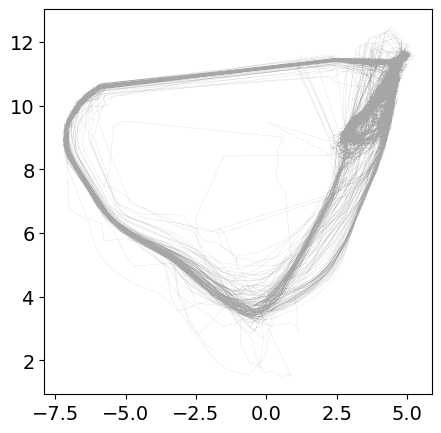

In [25]:
# Check how the UMAP projection looks
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(stoch_filenames))
trk_len_ode = int(len(embedding_all_prot)/len(stoch_filenames))

pos = 5

plt.plot(embedding_all_prot[pos*trk_len:(pos+1)*trk_len,0], embedding_all_prot[pos*trk_len:(pos+1)*trk_len,1], 
         lw=0.1, alpha=0.7, c='gray')



In [26]:
# We don't need the full runs from the ODE solutions for the UMAP, we can use a shortened segment of the run
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_ode)/len(ode_filenames)
sp = 1
for n in range(len(ode_filenames)):
    tmp = all_prot_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [27]:
all_prot_tmp_ode_ab.shape

(12000, 720)

### Generate embedding of ODE solutions

In [28]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [29]:
# Save all the outputs
if SET_JPARAM:
    if  not Path(SAVE_DIR, f'all_embedding_ode_conds_psoparams_{sys_name}.sav').exists() or OVERWRITE:
        print(f'Saving UMAP embeddings for pso parameters on a {sys_name} system.')
        joblib.dump(embedding_all_prot_ode, Path(SAVE_DIR, f'all_embedding_ode_cdk46i_psoparams_{sys_name}.sav'))
        joblib.dump(embedding_all_prot, Path(SAVE_DIR, f'all_embedding_stoch_cdk46i_psoparams_{sys_name}.sav'))
        joblib.dump(all_prot_tmp, Path(SAVE_DIR, f'all_prot_stoch_cdk46i_psoparams_{sys_name}.sav'))
        joblib.dump(all_time_tmp, Path(SAVE_DIR, f'all_time_cdk46i_tmp_{sys_name}_psoparams_{sys_name}.sav'))
else:
    if  not Path(SAVE_DIR, f'all_embedding_ode_cdk46i_{sys_name}.sav').exists() or OVERWRITE:
        print(f'Saving UMAP embeddings of CDK4/6i conditions on a {sys_name} system.')
        joblib.dump(embedding_all_prot_ode, Path(SAVE_DIR, f'all_embedding_ode_cdk46i_{sys_name}.sav'))
        joblib.dump(embedding_all_prot, Path(SAVE_DIR, f'all_embedding_stoch_cdk46i_{sys_name}.sav'))
        joblib.dump(all_prot, Path(SAVE_DIR, f'all_prot_stoch_cdk46i_{sys_name}.sav'))
        joblib.dump(all_time, Path(SAVE_DIR, f'all_time_cdk46i_tmp_{sys_name}.sav'))



